# Loan Default Prediction – EDA, SMOTE & Model Comparison

**Objective:** Explore the loan dataset, prepare it for machine learning, handle class imbalance using SMOTE on training data only, and compare:
1. Logistic Regression
2. Decision Tree
3. Random Forest

**Target column:** `Default` (0 = No Default, 1 = Default)

> Run the notebook from top to bottom. The notebook uses a preprocessing pipeline so that imputation, encoding, scaling, and SMOTE are fitted only on the training data. The test set remains untouched to avoid data leakage.

## 1. Import Required Libraries

Import libraries for data handling, visualization, preprocessing, SMOTE, model training, and evaluation.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load the Dataset

Update `DATA_PATH` if your CSV file is stored in a different folder. The uploaded dataset is expected to be named `Loan_Dataset(2).csv`.

In [4]:
DATA_PATH = "Loan_Dataset.csv"

if not os.path.exists(DATA_PATH):
    # Also check the common data folder used in project structures
    alternative_path = os.path.join("data", "Loan_Dataset(2).csv")
    if os.path.exists(alternative_path):
        DATA_PATH = alternative_path
    else:
        raise FileNotFoundError(
            f"Could not find {DATA_PATH}. Put the CSV beside this notebook "
            "or update DATA_PATH with the correct file path."
        )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (255447, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56.00,"85,994.00",50587,520.00,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69.00,"50,432.00",124440,458.00,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46.00,"84,208.00",129188,451.00,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32.00,"31,713.00",44799,743.00,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60.00,"20,437.00",9139,633.00,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


## 3. Understand the Dataset Structure

Check the first and last records, dimensions, column names, data types, and general information.

In [5]:
print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Number of rows and columns:", df.shape)

print("Column names:")
print(df.columns.tolist())

print("Data types and non-null counts:")
df.info()

First 5 rows:


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56.00,"85,994.00",50587,520.00,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69.00,"50,432.00",124440,458.00,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46.00,"84,208.00",129188,451.00,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32.00,"31,713.00",44799,743.00,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60.00,"20,437.00",9139,633.00,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


Last 5 rows:


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
255442,Q0FJ0D4L58,49.00,"129,281.00",45780,368.00,17,1,6.86,24,0.60,Bachelor's,Part-time,Divorced,No,Yes,Home,No,0
255443,PVWIF2218G,68.00,"110,889.00",72861,476.00,22,2,17.74,36,0.27,High School,Unemployed,Single,No,No,Home,Yes,0
255444,7JD8G10BT5,25.00,"48,235.00",50924,443.00,56,4,16.03,60,0.42,High School,Unemployed,Divorced,Yes,No,Business,Yes,0
255445,HEAZJ8SO5Q,27.00,"125,527.00",62232,826.00,31,4,9.36,36,0.31,Master's,Self-employed,Married,No,No,Auto,No,0
255446,3PJR5YIPYW,51.00,"80,963.00",103158,675.00,7,2,17.27,48,0.22,Master's,Full-time,Married,No,No,Home,No,0


Number of rows and columns: (255447, 18)
Column names:
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']
Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255447 entries, 0 to 255446
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255447 non-null  object 
 1   Age             254170 non-null  float64
 2   Income          254170 non-null  float64
 3   LoanAmount      255447 non-null  int64  
 4   CreditScore     254170 non-null  float64
 5   MonthsEmployed  255447 non-null  int64  
 6   NumCreditLines  255447 non-null  int64  
 7   InterestRate    254170 non-null  float64
 8   LoanTerm        255447 non-null  int64  
 9   DTIRatio        255447 non-null  floa

## 4. Descriptive Statistics

For numerical columns, review count, mean, standard deviation, minimum, quartiles, and maximum. Use `include='all'` to also inspect categorical columns.

In [6]:
display(df.describe().T)
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
Age,"254,170.00",43.50,14.99,18.00,31.00,43.00,56.00,69.00
Income,"254,170.00","82,502.51","38,965.51","15,000.00","48,821.00","82,480.50","116,227.00","149,999.00"
LoanAmount,"255,447.00","127,577.85","70,839.06","5,000.00","66,156.50","127,554.00","188,976.00","249,999.00"
CreditScore,"254,170.00",574.29,158.91,300.00,437.00,574.00,712.00,849.00
MonthsEmployed,"255,447.00",59.54,34.64,0.00,30.00,60.00,90.00,119.00
NumCreditLines,"255,447.00",2.50,1.12,1.00,2.00,2.00,3.00,4.00
InterestRate,"254,170.00",13.49,6.64,2.00,7.77,13.46,19.25,25.00
LoanTerm,"255,447.00",36.03,16.97,12.00,24.00,36.00,48.00,60.00
DTIRatio,"255,447.00",0.50,0.23,0.10,0.30,0.50,0.70,0.90
Default,"255,447.00",0.12,0.32,0.00,0.00,0.00,0.00,1.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
LoanID,255447,255347,UDHJLRJA2H,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"254,170.00",NaN,NaN,NaN,43.50,14.99,18.00,31.00,43.00,56.00,69.00
Income,"254,170.00",NaN,NaN,NaN,"82,502.51","38,965.51","15,000.00","48,821.00","82,480.50","116,227.00","149,999.00"
LoanAmount,"255,447.00",NaN,NaN,NaN,"127,577.85","70,839.06","5,000.00","66,156.50","127,554.00","188,976.00","249,999.00"
CreditScore,"254,170.00",NaN,NaN,NaN,574.29,158.91,300.00,437.00,574.00,712.00,849.00
MonthsEmployed,"255,447.00",NaN,NaN,NaN,59.54,34.64,0.00,30.00,60.00,90.00,119.00
NumCreditLines,"255,447.00",NaN,NaN,NaN,2.50,1.12,1.00,2.00,2.00,3.00,4.00
InterestRate,"254,170.00",NaN,NaN,NaN,13.49,6.64,2.00,7.77,13.46,19.25,25.00
LoanTerm,"255,447.00",NaN,NaN,NaN,36.03,16.97,12.00,24.00,36.00,48.00,60.00
DTIRatio,"255,447.00",NaN,NaN,NaN,0.50,0.23,0.10,0.30,0.50,0.70,0.90


## 5. Missing Value Analysis

Calculate missing-value counts and percentages. The bar chart makes it easier to identify columns that need attention.

,Missing_Count,Missing_Percentage
Income,1277,0.50
CreditScore,1277,0.50
InterestRate,1277,0.50
Age,1277,0.50
Education,1277,0.50
EmploymentType,1277,0.50


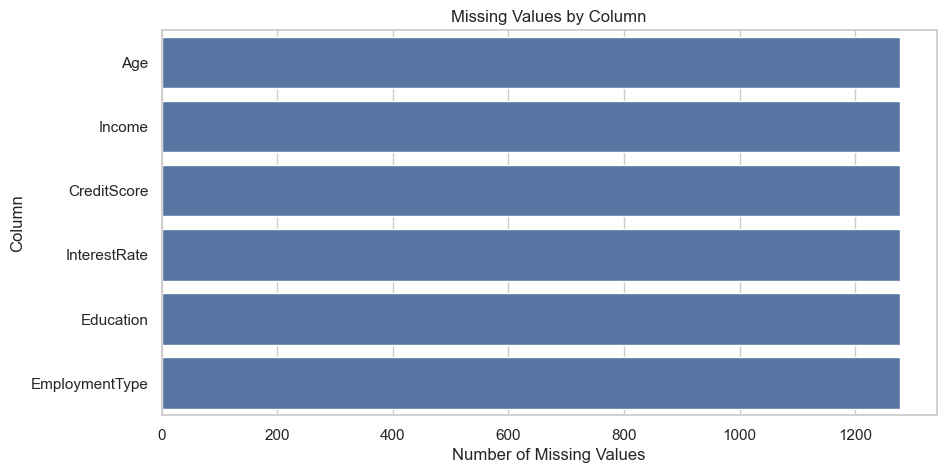

In [7]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_summary[missing_summary["Missing_Count"] > 0])

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

if len(missing_counts) > 0:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_counts.values, y=missing_counts.index)
    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.show()
else:
    print("No missing values found.")

## 6. Duplicate Record Analysis

Count exact duplicate rows before removing them. Then remove duplicates and verify the new shape.

In [8]:
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Exact duplicate rows: 100
Shape after removing duplicates: (255347, 18)
Duplicates remaining: 0


## 7. Check Target Variable and Class Imbalance

Inspect the distribution of `Default`. A strong difference between class counts indicates class imbalance. We will address it later with SMOTE, applied only to the training data.

Target value counts:


,Count
Default,
0,225694
1,29653


Target percentages:


,Percentage
Default,
0,88.39
1,11.61


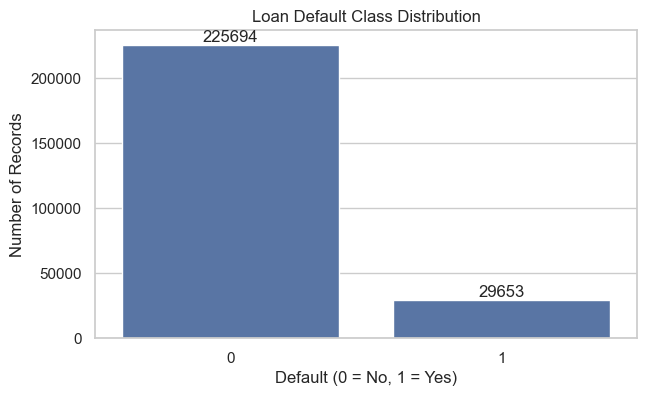

In [9]:
TARGET = "Default"

if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' was not found. Available columns: {df.columns.tolist()}")

print("Target value counts:")
display(df[TARGET].value_counts().rename_axis("Default").to_frame("Count"))

print("Target percentages:")
display((df[TARGET].value_counts(normalize=True) * 100).round(2).rename("Percentage").to_frame())

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x=TARGET)
ax.set_title("Loan Default Class Distribution")
ax.set_xlabel("Default (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Records")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.show()

## 8. Validate Values and Data Types

Review numeric ranges and categorical labels. These checks help identify impossible or unexpected values before modelling. They are diagnostic checks; do not automatically delete a row just because it is an outlier.

In [10]:
print("Numeric summary:")
display(df.select_dtypes(include=np.number).describe().T)

print("Unique values in categorical columns:")
categorical_cols_all = df.select_dtypes(include="object").columns.tolist()
for col in categorical_cols_all:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))

# Basic domain checks for common loan attributes
range_checks = {}
for col in ["Age", "Income", "LoanAmount", "CreditScore", "MonthsEmployed",
            "NumCreditLines", "InterestRate", "LoanTerm", "DTIRatio"]:
    if col in df.columns:
        range_checks[col] = {
            "Minimum": df[col].min(),
            "Maximum": df[col].max(),
            "Negative_Count": int((df[col] < 0).sum())
        }

display(pd.DataFrame(range_checks).T)

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Age,"254,070.00",43.50,14.99,18.00,31.00,43.00,56.00,69.00
Income,"254,070.00","82,501.92","38,963.81","15,000.00","48,826.00","82,479.50","116,223.00","149,999.00"
LoanAmount,"255,347.00","127,578.87","70,840.71","5,000.00","66,156.00","127,556.00","188,985.00","249,999.00"
CreditScore,"254,070.00",574.28,158.91,300.00,437.00,574.00,712.00,849.00
MonthsEmployed,"255,347.00",59.54,34.64,0.00,30.00,60.00,90.00,119.00
NumCreditLines,"255,347.00",2.50,1.12,1.00,2.00,2.00,3.00,4.00
InterestRate,"254,070.00",13.49,6.64,2.00,7.77,13.46,19.25,25.00
LoanTerm,"255,347.00",36.03,16.97,12.00,24.00,36.00,48.00,60.00
DTIRatio,"255,347.00",0.50,0.23,0.10,0.30,0.50,0.70,0.90
Default,"255,347.00",0.12,0.32,0.00,0.00,0.00,0.00,1.00


Unique values in categorical columns:

LoanID:
LoanID
I38PQUQS96    1
WGB0GD3150    1
XATSFC5YHN    1
CQXDW5VBAG    1
6AIVUNAJG8    1
CAOM3190ND    1
OPSTKKWJ3U    1
RV2BE601XX    1
THMS88YJHR    1
NCPNUWWUBE    1
48WHAABCI5    1
7VRTMNBT2M    1
1MIOJ7EYYE    1
E1J0VYDD98    1
10OKJ85X37    1
PEJDATT9KR    1
L8SCW4UM1N    1
8FUJC19TKS    1
AFATF3JQ01    1
QXR8CW5QVE    1
Name: count, dtype: int64

Education:
Education
Bachelor's     64047
High School    63573
Master's       63231
PhD            63219
NaN             1277
Name: count, dtype: int64

EmploymentType:
EmploymentType
Part-time        63834
Unemployed       63515
Self-employed    63368
Full-time        63353
NaN               1277
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

HasMortgage:
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

HasDependents:
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64


,Minimum,Maximum,Negative_Count
Age,18.00,69.00,0.00
Income,"15,000.00","149,999.00",0.00
LoanAmount,"5,000.00","249,999.00",0.00
CreditScore,300.00,849.00,0.00
MonthsEmployed,0.00,119.00,0.00
NumCreditLines,1.00,4.00,0.00
InterestRate,2.00,25.00,0.00
LoanTerm,12.00,60.00,0.00
DTIRatio,0.10,0.90,0.00


## 9. Univariate Analysis – Numerical Features

Use histograms and boxplots to understand the distribution and spread of numeric variables. Boxplot points may indicate potential outliers, not necessarily errors.

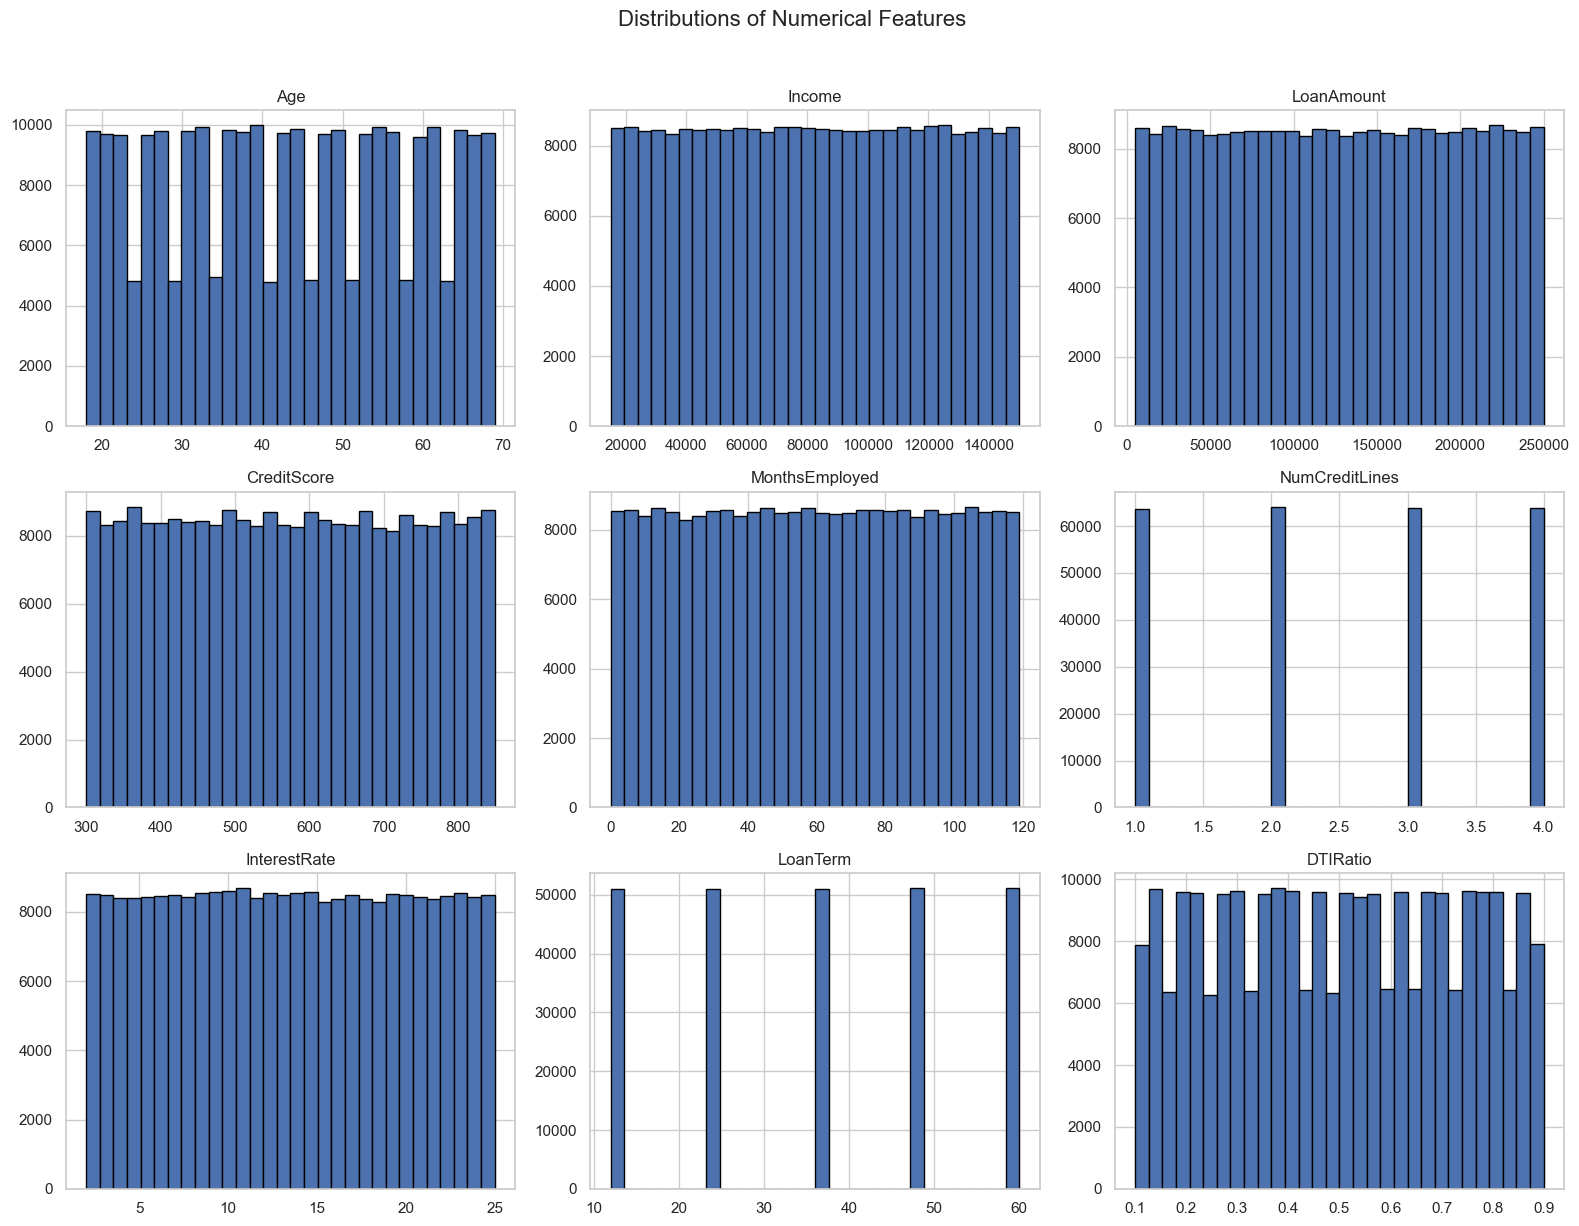

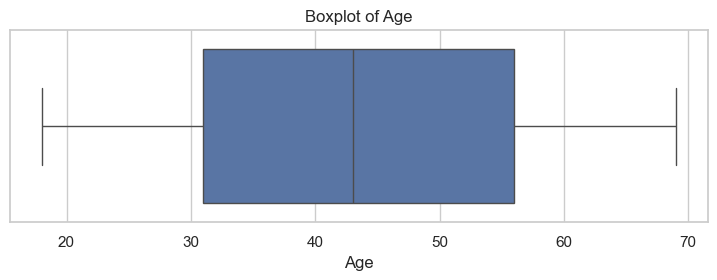

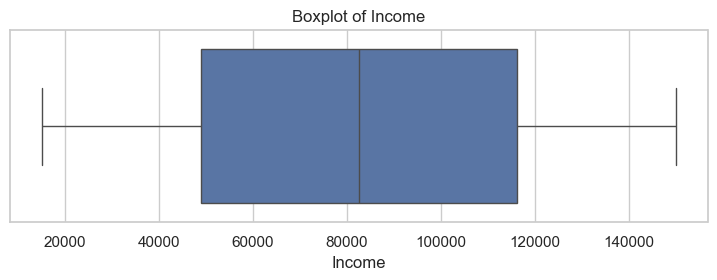

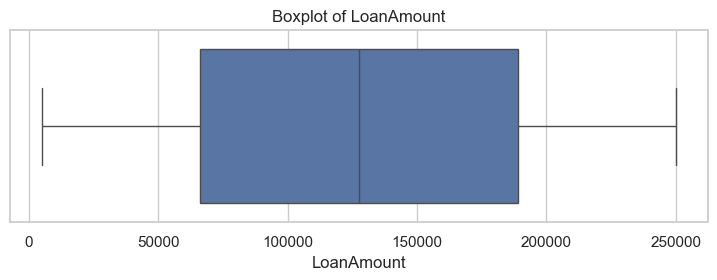

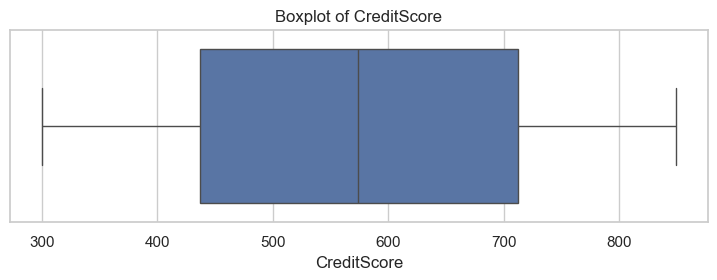

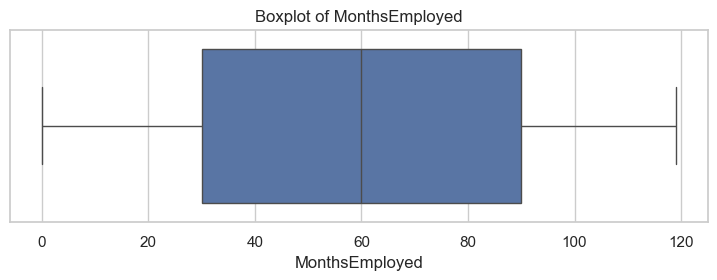

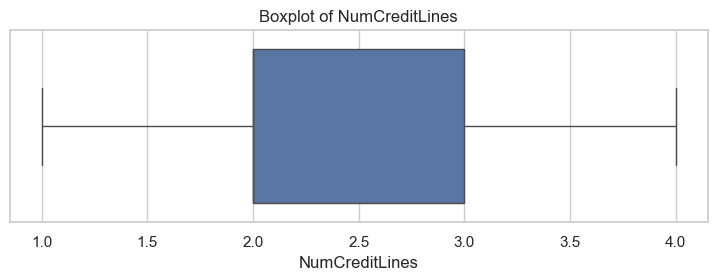

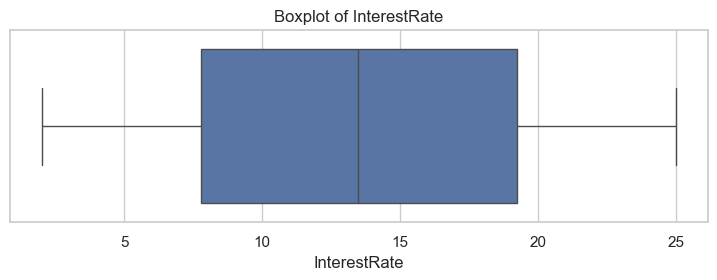

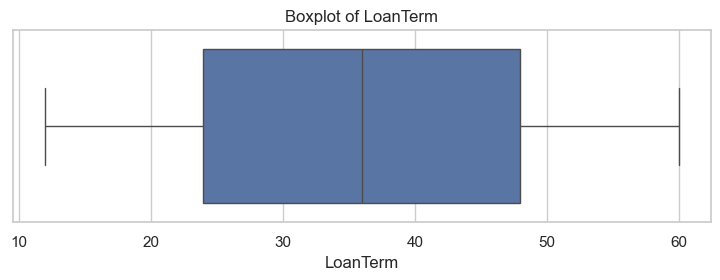

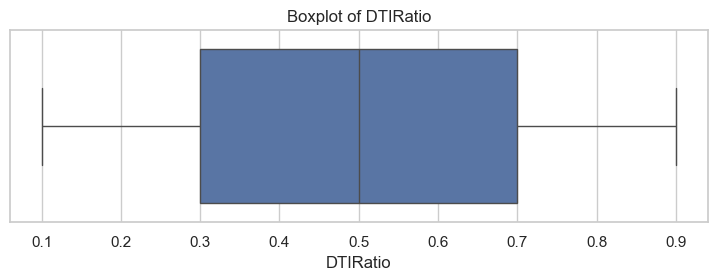

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns.drop(TARGET, errors="ignore").tolist()

df[numeric_cols].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

for col in numeric_cols:
    plt.figure(figsize=(9, 2.5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

## 10. Correlation Analysis

Calculate correlations between numerical columns and display a heatmap. Correlation indicates association, not causation.

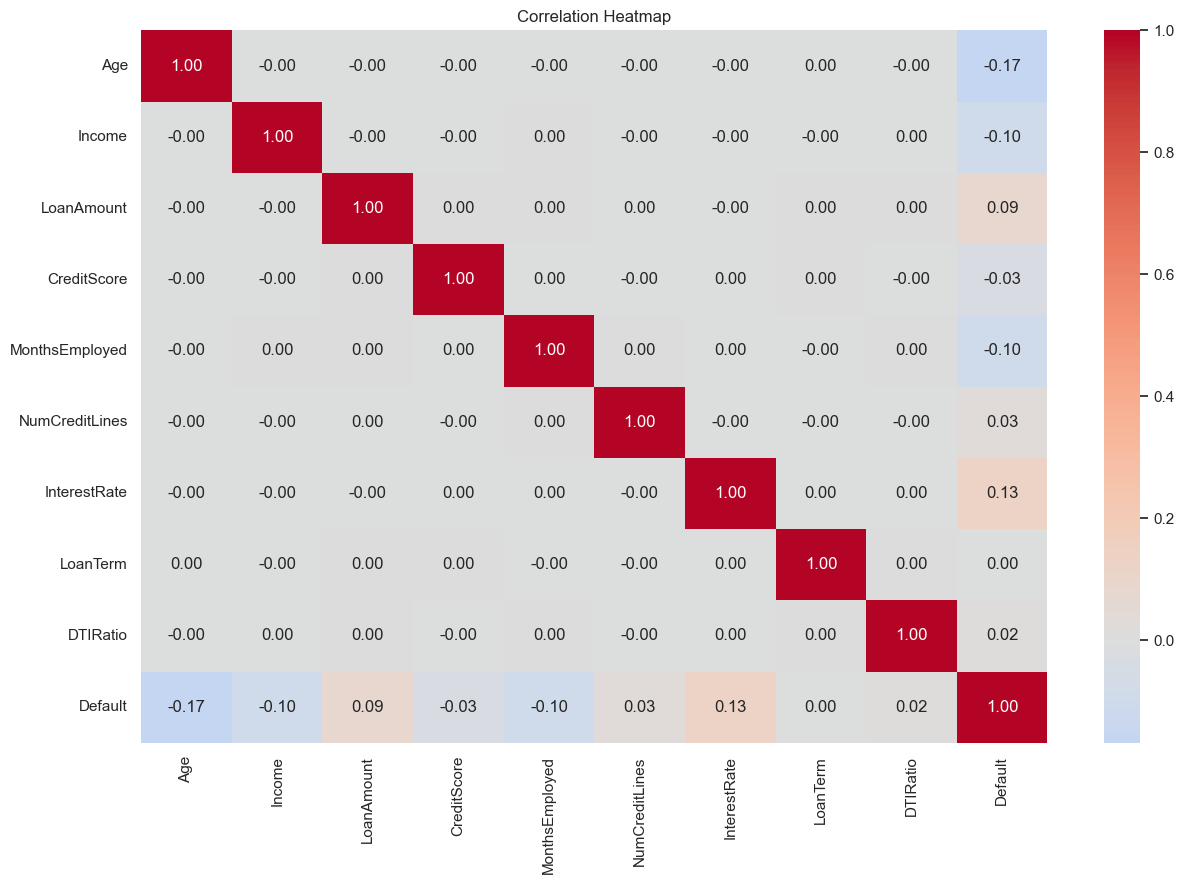

Numerical features most correlated with Default (absolute correlation):


,Correlation_with_Default
Age,-0.17
InterestRate,0.13
Income,-0.10
MonthsEmployed,-0.10
LoanAmount,0.09
CreditScore,-0.03
NumCreditLines,0.03
DTIRatio,0.02
LoanTerm,0.00


In [12]:
corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(13, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Numerical features most correlated with Default (absolute correlation):")
display(target_corr.to_frame("Correlation_with_Default"))

## 11. Compare Features Across Default Classes

Use boxplots to compare numeric feature distributions for default and non-default borrowers. These plots can reveal differences worth investigating.

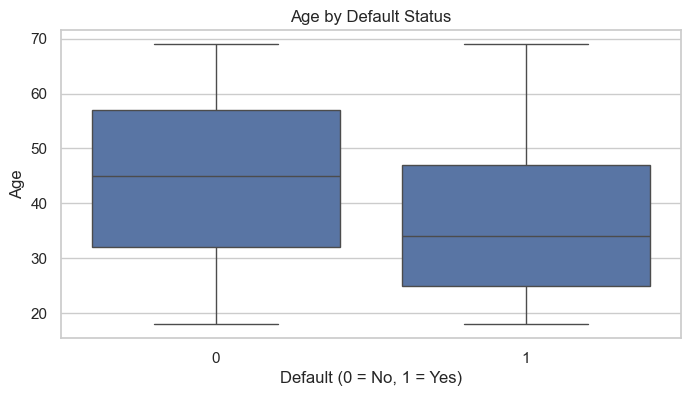

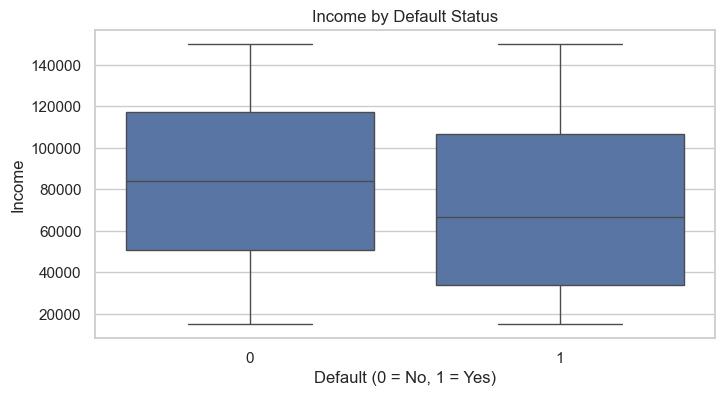

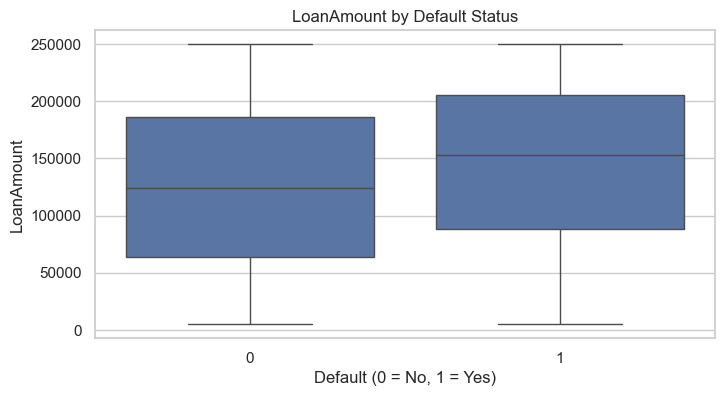

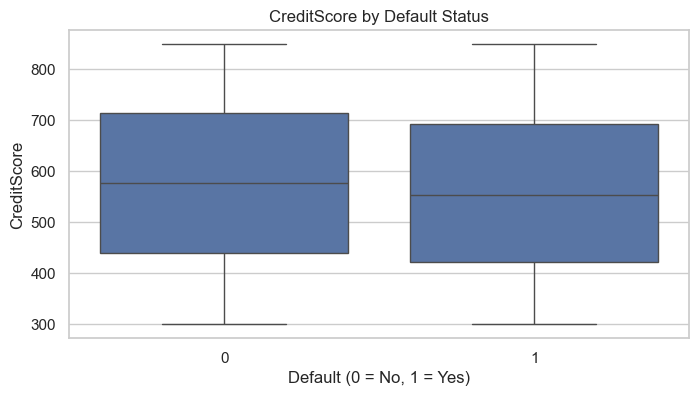

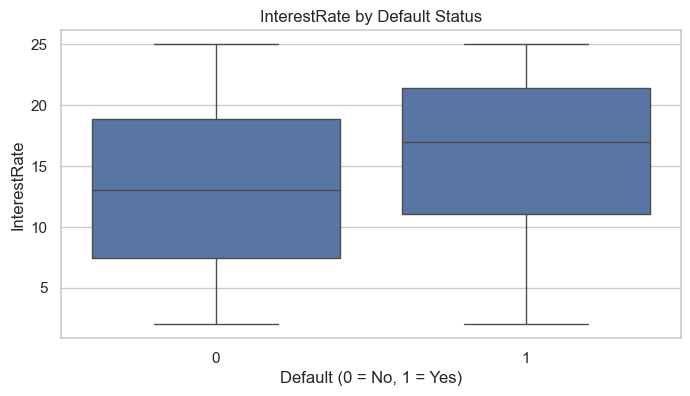

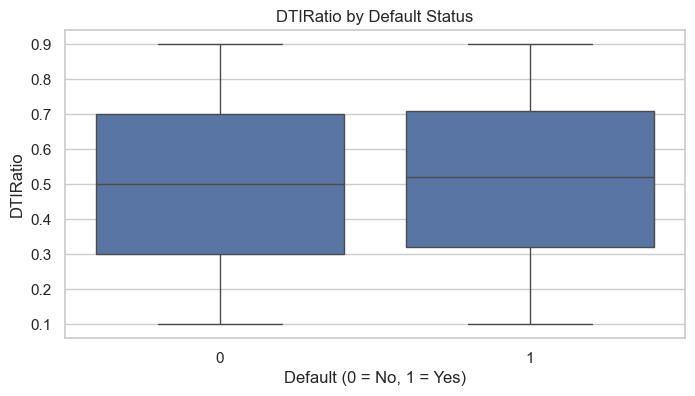

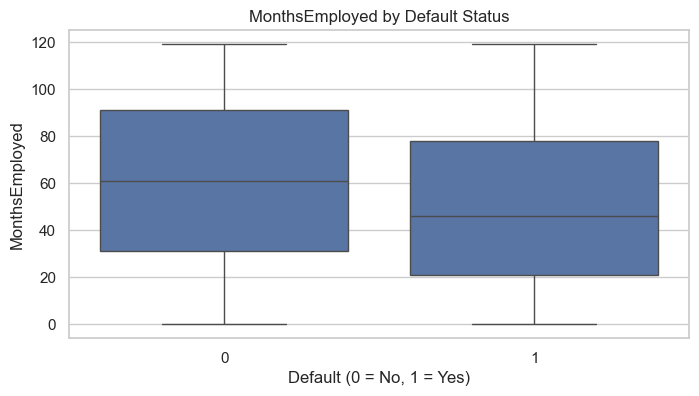

In [13]:
features_to_compare = [c for c in
    ["Age", "Income", "LoanAmount", "CreditScore", "InterestRate", "DTIRatio", "MonthsEmployed"]
    if c in df.columns]

for col in features_to_compare:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x=TARGET, y=col)
    plt.title(f"{col} by Default Status")
    plt.xlabel("Default (0 = No, 1 = Yes)")
    plt.show()

## 12. Outlier Review Using the IQR Method

Calculate the number and percentage of potential outliers in each numeric feature using the 1.5 × IQR rule. We will review them rather than remove them automatically, because unusually large loan amounts or incomes may be genuine.

In [14]:
outlier_rows = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": int(count),
        "Outlier_Percentage": round(count / len(df) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("Outlier_Count", ascending=False)
display(outlier_summary)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Age,-6.50,93.50,0,0.00
1,Income,"-52,269.50","217,318.50",0,0.00
2,LoanAmount,"-118,087.50","373,228.50",0,0.00
3,CreditScore,24.50,"1,124.50",0,0.00
4,MonthsEmployed,-60.00,180.00,0,0.00
5,NumCreditLines,0.50,4.50,0,0.00
6,InterestRate,-9.45,36.47,0,0.00
7,LoanTerm,-12.00,84.00,0,0.00
8,DTIRatio,-0.30,1.30,0,0.00


## 13. Prepare Features and Target

Remove `LoanID` because it is an identifier, not a meaningful borrower risk feature. Keep the target separate from the predictors.

In [15]:
drop_columns = [TARGET]
if "LoanID" in df.columns:
    drop_columns.append("LoanID")

X = df.drop(columns=drop_columns)
y = df[TARGET].astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.unique()))

if not set(y.unique()).issubset({0, 1}):
    raise ValueError("Default must contain only 0 and 1.")

Feature matrix shape: (255347, 16)
Target shape: (255347,)
Target classes: [np.int64(0), np.int64(1)]


## 14. Train-Test Split

Split the data into 80% training and 20% testing. `stratify=y` preserves approximately the same target-class proportions in both sets.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2).rename("Percentage").to_frame())

print("Testing target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2).rename("Percentage").to_frame())

Training features: (204277, 16)
Testing features: (51070, 16)

Training target distribution:


,Percentage
Default,
0,88.39
1,11.61


Testing target distribution:


,Percentage
Default,
0,88.39
1,11.61


## 15. Define Preprocessing

Numeric columns: fill missing values with the median and standardize them.

Categorical columns: fill missing values with the most frequent category and apply one-hot encoding.

The preprocessing is placed inside each model pipeline. It is therefore fitted on training data only.

In [17]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']
Categorical features: ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


## 16. Apply SMOTE to the Training Data Only

SMOTE creates synthetic minority-class examples to reduce class imbalance. It must be applied **after the train-test split** and only within the training pipeline. This keeps the test set representative of unseen data and prevents data leakage.

The pipeline order is:
1. Impute, encode, and scale
2. Apply SMOTE to training data
3. Fit the classifier

In [18]:
print("Before SMOTE:")
display(y_train.value_counts().rename("Count").to_frame())

# Demonstrate the expected balanced class counts after SMOTE.
# Actual resampling occurs inside each model pipeline during .fit().
print("\nSMOTE will be applied inside each training pipeline.")
print("Test-set class counts remain unchanged:")
display(y_test.value_counts().rename("Count").to_frame())

Before SMOTE:


,Count
Default,
0,180555
1,23722



SMOTE will be applied inside each training pipeline.
Test-set class counts remain unchanged:


,Count
Default,
0,45139
1,5931


## 17. Build the Three Model Pipelines

All three models use the same preprocessing and SMOTE strategy to make the comparison fair. `class_weight` is not additionally used because SMOTE is already addressing the imbalance.

In [19]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=None,
        min_samples_split=2
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

model_pipelines = {}

for model_name, estimator in models.items():
    model_pipelines[model_name] = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", estimator)
    ])

print("Created pipelines:", list(model_pipelines.keys()))

Created pipelines: ['Logistic Regression', 'Decision Tree', 'Random Forest']


## 18. Train Models and Generate Predictions

Fit each pipeline using only the training data. Predict the held-out test set and calculate probability scores for ROC-AUC.

In [20]:
trained_models = {}
predictions = {}
probabilities = {}

for model_name, pipeline in model_pipelines.items():
    print(f"Training {model_name}...")
    pipeline.fit(X_train, y_train)

    trained_models[model_name] = pipeline
    predictions[model_name] = pipeline.predict(X_test)

    if hasattr(pipeline, "predict_proba"):
        probabilities[model_name] = pipeline.predict_proba(X_test)[:, 1]
    else:
        probabilities[model_name] = None

print("All models trained.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
All models trained.


## 19. Classification Evaluation Metrics

Compare the models using:
- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Of predicted defaults, how many were actual defaults.
- **Recall:** Of actual defaults, how many the model detected.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Ability to rank default cases above non-default cases.

For a loan-default problem, do not rely on accuracy alone. Recall and precision are important because false negatives and false positives can have different business costs.

In [21]:
results = []

for model_name in trained_models:
    y_pred = predictions[model_name]
    y_prob = probabilities[model_name]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1_Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1_Score", ascending=False)
display(results_df.style.format("{:.4f}"))

,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Model,,,,,
Logistic Regression,0.6826,0.2218,0.6909,0.3358,0.7529
Decision Tree,0.7732,0.1846,0.2787,0.2221,0.5585
Random Forest,0.8793,0.4250,0.1118,0.1770,0.7393


## 20. Classification Reports

The classification report provides precision, recall, F1-score, and support for each class separately. Pay particular attention to class `1`, which represents loan default.

In [22]:
for model_name in trained_models:
    print("=" * 70)
    print(model_name)
    print("=" * 70)
    print(classification_report(
        y_test,
        predictions[model_name],
        target_names=["No Default (0)", "Default (1)"],
        zero_division=0
    ))

Logistic Regression
                precision    recall  f1-score   support

No Default (0)       0.94      0.68      0.79     45139
   Default (1)       0.22      0.69      0.34      5931

      accuracy                           0.68     51070
     macro avg       0.58      0.69      0.56     51070
  weighted avg       0.86      0.68      0.74     51070

Decision Tree
                precision    recall  f1-score   support

No Default (0)       0.90      0.84      0.87     45139
   Default (1)       0.18      0.28      0.22      5931

      accuracy                           0.77     51070
     macro avg       0.54      0.56      0.54     51070
  weighted avg       0.82      0.77      0.79     51070

Random Forest
                precision    recall  f1-score   support

No Default (0)       0.89      0.98      0.93     45139
   Default (1)       0.42      0.11      0.18      5931

      accuracy                           0.88     51070
     macro avg       0.66      0.55      0.56   

## 21. Confusion Matrices

A confusion matrix shows:
- True Negative (TN): correctly predicted non-default
- False Positive (FP): non-default incorrectly flagged as default
- False Negative (FN): default incorrectly predicted as non-default
- True Positive (TP): correctly detected default

Compare the false negatives carefully because they represent borrowers who defaulted but were not identified by the model.

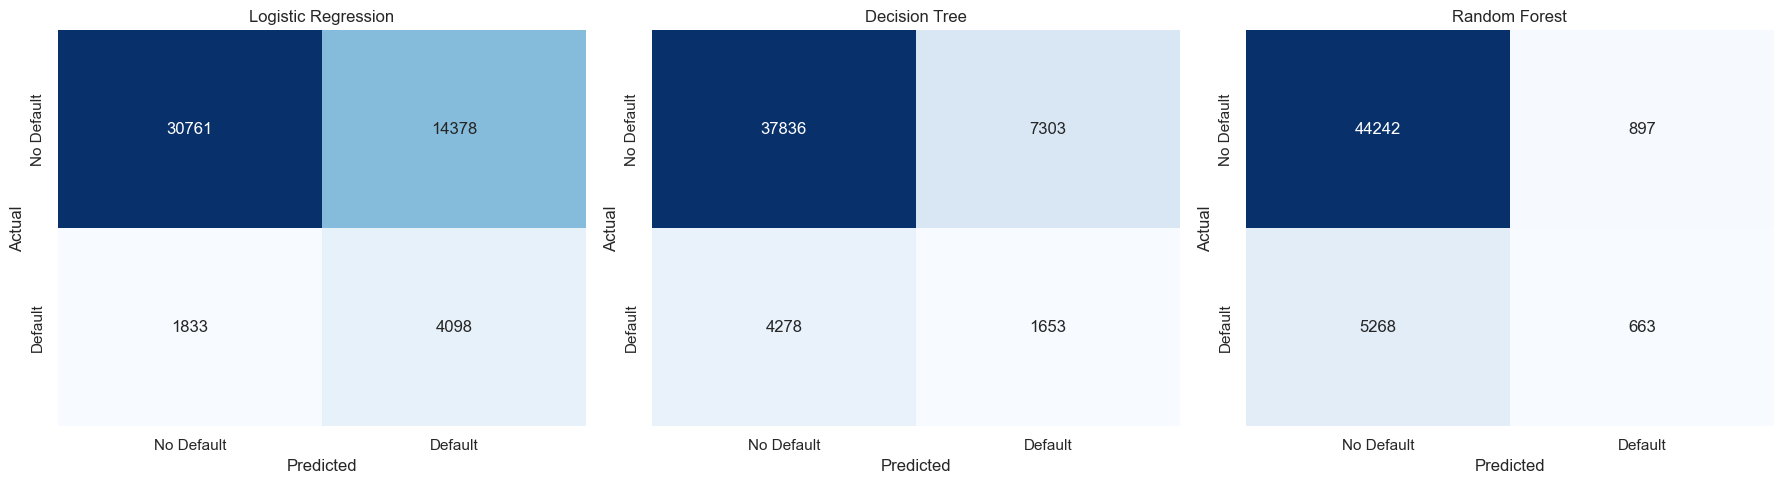

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, model_name in zip(axes, trained_models):
    cm = confusion_matrix(y_test, predictions[model_name])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["No Default", "Default"],
        yticklabels=["No Default", "Default"]
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 22. ROC Curves

ROC curves compare true-positive rate against false-positive rate across classification thresholds. A higher ROC-AUC generally indicates better ranking ability.

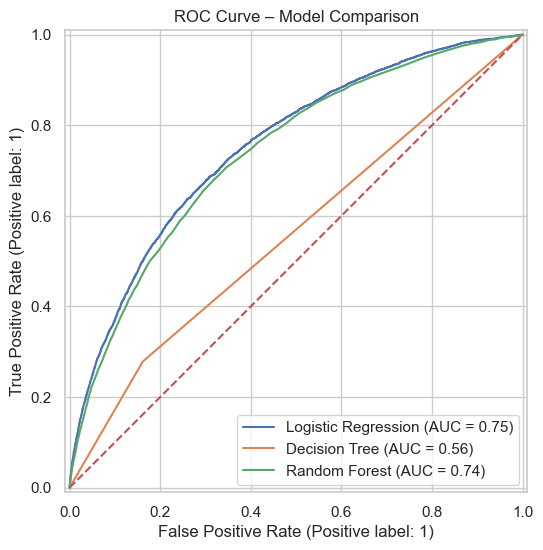

In [24]:
plt.figure(figsize=(8, 6))

for model_name in trained_models:
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[model_name],
        name=model_name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve – Model Comparison")
plt.show()

## 23. Compare Evaluation Metrics Visually

The bar charts make it easier to compare the models across the selected classification metrics.

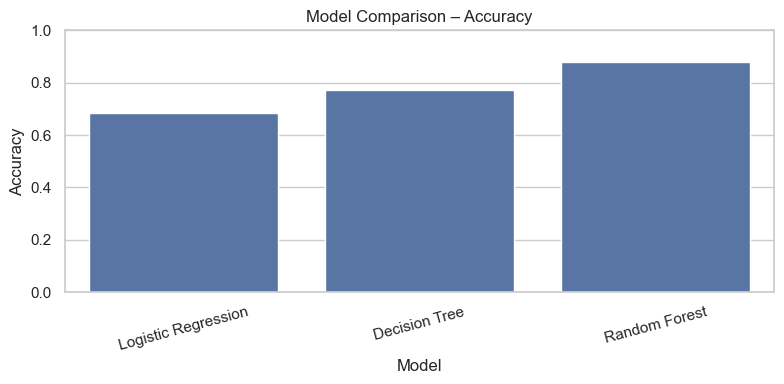

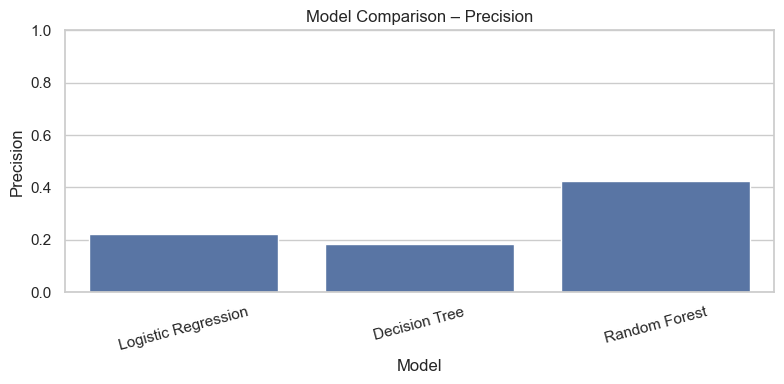

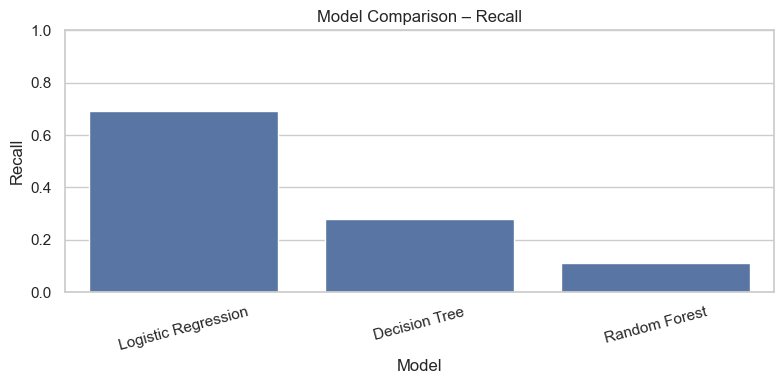

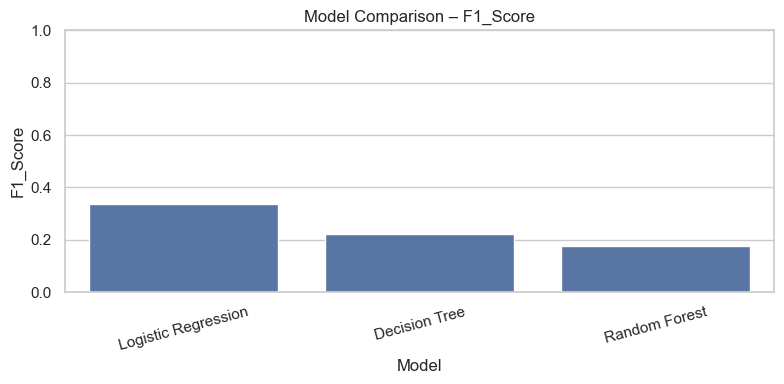

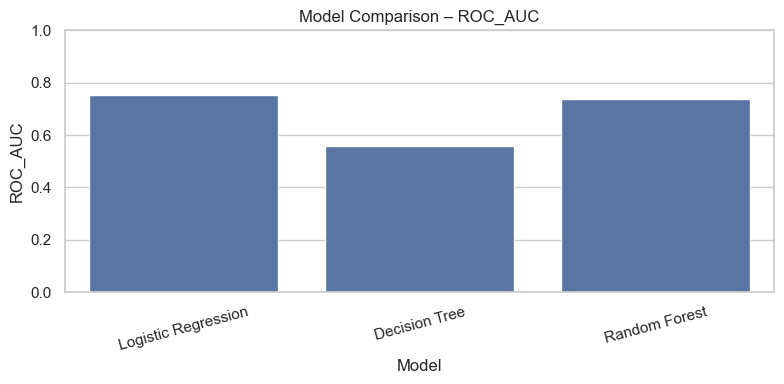

In [25]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]

for metric in metrics_to_plot:
    plt.figure(figsize=(8, 4))
    sns.barplot(
        x=results_df.index,
        y=results_df[metric]
    )
    plt.title(f"Model Comparison – {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 24. Select the Best Model Based on F1-score

This notebook selects the model with the highest F1-score as the default comparison winner. This is a practical starting point for balancing precision and recall, but the final business choice should reflect the cost of missed defaults versus incorrectly rejecting good borrowers.

In [26]:
best_model_name = results_df["F1_Score"].idxmax()
best_model = trained_models[best_model_name]

print("Best model based on F1-score:", best_model_name)
print("\nBest model metrics:")
display(results_df.loc[[best_model_name]].style.format("{:.4f}"))

Best model based on F1-score: Logistic Regression

Best model metrics:


,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Model,,,,,
Logistic Regression,0.6826,0.2218,0.6909,0.3358,0.7529


## 25. Feature Importance – Tree Models

For Decision Tree and Random Forest, display their feature importance values after preprocessing. One-hot encoding expands categorical columns, so the feature names are retrieved from the fitted preprocessor.

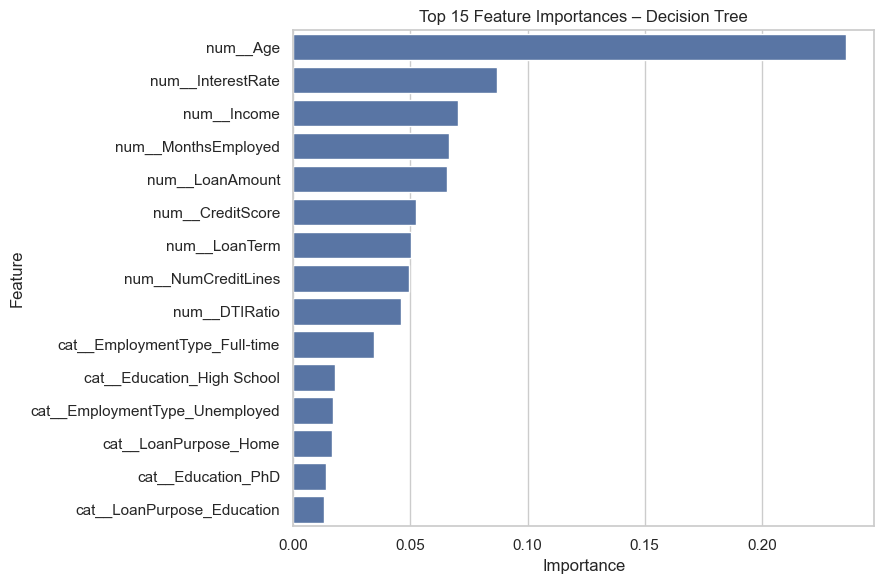

,Feature,Importance
0,num__Age,0.24
6,num__InterestRate,0.09
1,num__Income,0.07
4,num__MonthsEmployed,0.07
2,num__LoanAmount,0.07
3,num__CreditScore,0.05
7,num__LoanTerm,0.05
5,num__NumCreditLines,0.05
8,num__DTIRatio,0.05
13,cat__EmploymentType_Full-time,0.03


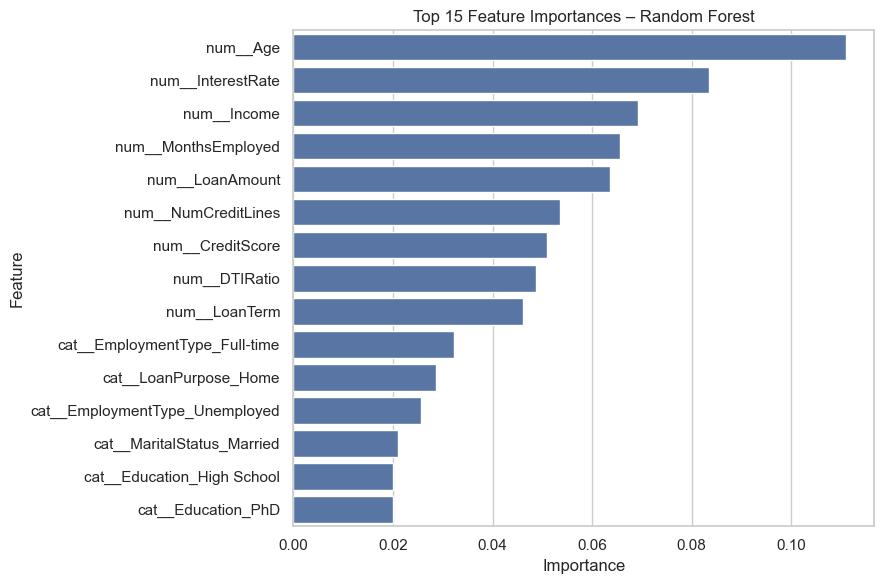

,Feature,Importance
0,num__Age,0.11
6,num__InterestRate,0.08
1,num__Income,0.07
4,num__MonthsEmployed,0.07
2,num__LoanAmount,0.06
5,num__NumCreditLines,0.05
3,num__CreditScore,0.05
8,num__DTIRatio,0.05
7,num__LoanTerm,0.05
13,cat__EmploymentType_Full-time,0.03


In [27]:
def get_transformed_feature_names(fitted_preprocessor):
    try:
        return fitted_preprocessor.get_feature_names_out()
    except Exception:
        return np.array([f"Feature_{i}" for i in range(
            len(fitted_preprocessor.transform(X_train.iloc[:1]).toarray()[0])
            if hasattr(fitted_preprocessor.transform(X_train.iloc[:1]), "toarray")
            else fitted_preprocessor.transform(X_train.iloc[:1]).shape[1]
        )])

for model_name in ["Decision Tree", "Random Forest"]:
    fitted_pipeline = trained_models[model_name]
    estimator = fitted_pipeline.named_steps["model"]

    if hasattr(estimator, "feature_importances_"):
        feature_names = get_transformed_feature_names(
            fitted_pipeline.named_steps["preprocessor"]
        )
        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": estimator.feature_importances_
        }).sort_values("Importance", ascending=False).head(15)

        plt.figure(figsize=(9, 6))
        sns.barplot(data=importance_df, x="Importance", y="Feature")
        plt.title(f"Top 15 Feature Importances – {model_name}")
        plt.tight_layout()
        plt.show()
        display(importance_df)

## 26. Save Results and the Best Pipeline

Save the comparison table and fitted best pipeline. The saved pipeline includes preprocessing and the fitted classifier. SMOTE is used during training but is not applied when making predictions.

In [28]:
import joblib

os.makedirs("outputs", exist_ok=True)

results_df.to_csv("outputs/model_comparison_metrics.csv")
joblib.dump(best_model, "outputs/best_loan_default_pipeline.joblib")

with open("outputs/best_model_name.txt", "w", encoding="utf-8") as file:
    file.write(best_model_name)

print("Saved:")
print("- outputs/model_comparison_metrics.csv")
print("- outputs/best_loan_default_pipeline.joblib")
print("- outputs/best_model_name.txt")

Saved:
- outputs/model_comparison_metrics.csv
- outputs/best_loan_default_pipeline.joblib
- outputs/best_model_name.txt


## 27. Final Conclusion

Use the results produced above to write your project conclusion. Include:
1. The original class distribution and why it was imbalanced.
2. How missing values and duplicate rows were handled.
3. Why SMOTE was applied only to training data.
4. Which model achieved the highest F1-score.
5. Which model achieved the highest recall and ROC-AUC.
6. Why accuracy alone is not sufficient for loan-default prediction.
7. The business trade-off between missing a defaulter (false negative) and flagging a safe borrower (false positive).

**Important:** Do not assume the model with the highest accuracy is automatically the best model. Choose evaluation metrics based on the lending business objective and risk tolerance.